# Expanded matched ML and QML model comparison

Self-contained five-stock expanded study. Shared sample and preprocessing methods are embedded below. It adds logistic regression, random forest, gradient boosting, kNN, MLP, Z-map QSVM and an optional projected quantum kernel. This experiment has not yet been executed in the saved workspace.

In [ ]:
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name.lower() == 'notebooks': ROOT = ROOT.parent
__file__ = str(ROOT / 'notebooks' / '13_expanded_models.ipynb')
assert (ROOT / 'data' / 'processed').exists(), f'Open this notebook from the project folder: {ROOT}'
RUN_EXPERIMENT = True  # True regenerates outputs and can take a long time
print('Project:', ROOT)

Project: E:\Quantum Project


## Shared data and preprocessing methods

### Imports, protocol and constants

In [2]:
"""Reproducible binary/three-class extension; legacy evidence remains unchanged."""
from pathlib import Path
import hashlib
import json
import time
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterGrid
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

THRESHOLD = 0.0025
TASKS = {'binary': ('target_up', [0, 1]), 'three_class': ('target_three', [0, 1, 2])}
CONFIG = dict(tickers=['AAPL','MSFT','JPM','XOM','JNJ'], train_dates=200,
              validation_dates=80, evaluation_dates=100, threshold=THRESHOLD,
              start='2015-01-01', validation_start='2021-01-01',
              evaluation_start='2023-01-01', end='2025-01-01', seed=42)



### Labels

In [3]:
def labels(returns):
    """Simple-return bands: DOWN=0, NEUTRAL=1, UP=2; missing stays missing."""
    r = pd.Series(returns)
    out = pd.Series(np.select([r < -THRESHOLD, r > THRESHOLD], [0, 2], default=1), index=r.index, dtype='Int64')
    return out.mask(r.isna())



### Digest

In [4]:
def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()



### Read Selected

In [5]:
def read_selected(path, columns):
    return pd.concat([c.loc[c.Ticker.isin(CONFIG['tickers'])] for c in
        pd.read_csv(path, usecols=columns, parse_dates=['Date'], chunksize=200000)], ignore_index=True).sort_values(['Ticker','Date'])



### Prepare

In [6]:
def prepare(root):
    features = json.loads((root/'data/processed/feature_columns.json').read_text())
    assert len(features)==16 and not any('target' in f or 'forward' in f for f in features)
    data = read_selected(root/'data/processed/SP500_features.csv', ['Ticker','Date',*features,'target_up'])
    target = read_selected(root/'data/processed/SP500_targets.csv', ['Ticker','Date','label_end','forward_return_simple','target_three'])
    target['label_end'] = pd.to_datetime(target.label_end)
    data = data.merge(target, on=['Ticker','Date'], validate='one_to_one')
    assert not data.duplicated(['Ticker','Date']).any()
    assert np.isfinite(data[features].to_numpy()).all()
    assert (data.label_end > data.Date).all()
    assert np.array_equal(data.target_up, (data.forward_return_simple>0).astype(int))
    assert np.array_equal(data.target_three, labels(data.forward_return_simple).astype(int))
    frames = {}
    for name, lo, hi, count in [
        ('train',CONFIG['start'],CONFIG['validation_start'],CONFIG['train_dates']),
        ('validation',CONFIG['validation_start'],CONFIG['evaluation_start'],CONFIG['validation_dates']),
        ('evaluation',CONFIG['evaluation_start'],CONFIG['end'],CONFIG['evaluation_dates'])]:
        frame = data.loc[(data.Date>=lo)&(data.Date<hi)&(data.label_end<hi)]
        dates = np.sort(frame.Date.unique())
        chosen = dates[np.linspace(0,len(dates)-1,min(count,len(dates)),dtype=int)]
        frames[name] = frame.loc[frame.Date.isin(chosen)].sort_values(['Date','Ticker']).reset_index(drop=True)
    frames['development'] = pd.concat([frames['train'],frames['validation']],ignore_index=True).sort_values(['Date','Ticker'])
    assert frames['train'].label_end.max()<frames['validation'].Date.min()
    assert frames['development'].label_end.max()<frames['evaluation'].Date.min()
    for frame in frames.values():
        assert set(frame.Ticker)==set(CONFIG['tickers'])
        for target_name, classes in TASKS.values():
            assert set(frame[target_name])==set(classes), 'Missing class: revise protocol before drawing conclusions'
            assert frame[target_name].value_counts().min()>=20, 'Insufficient per-class support'
    return features, frames



### Metrics

In [7]:
def metrics(y, pred):
    return dict(accuracy=accuracy_score(y,pred), balanced_accuracy=balanced_accuracy_score(y,pred),
        macro_f1=f1_score(y,pred,average='macro',zero_division=0),
        macro_precision=precision_score(y,pred,average='macro',zero_division=0),
        macro_recall=recall_score(y,pred,average='macro',zero_division=0))



### Grids

In [8]:
def grids(quantum):
    result = {'dummy':[{}], 'linear':list(ParameterGrid({'C':[0.1,1,10]})),
        'rbf':list(ParameterGrid({'C':[0.1,1,10],'gamma':['scale',0.01,0.1]})),
        'polynomial':list(ParameterGrid({'C':[0.1,1,10],'degree':[2,3],'gamma':['scale']}))}
    if quantum: result['qsvm'] = list(ParameterGrid({'C':[0.1,1,10]}))
    return result



### Model

In [9]:
def model(name, params):
    if name=='dummy': return DummyClassifier(strategy='most_frequent')
    return SVC(kernel={'linear':'linear','rbf':'rbf','polynomial':'poly','qsvm':'precomputed'}[name],
               class_weight='balanced', decision_function_shape='ovr', **params)



### Transforms

In [10]:
def transforms(d):
    steps=[('scale',StandardScaler())]
    if d != 16:
        steps += [('pca',PCA(n_components=d,svd_solver='full')),('angles',MinMaxScaler(feature_range=(-np.pi,np.pi),clip=True))]
    return Pipeline(steps)



### Kernel

In [11]:
def kernel(A,B,d):
    from qiskit.circuit.library import zz_feature_map
    from qiskit_machine_learning.kernels import FidelityStatevectorKernel
    from qiskit.quantum_info import Statevector
    circuit=zz_feature_map(d,reps=1,entanglement='linear')
    k=FidelityStatevectorKernel(feature_map=circuit,shots=None)
    start=time.perf_counter(); K=k.evaluate(A); fit_time=time.perf_counter()-start
    start=time.perf_counter(); cross=k.evaluate(B,A); cross_time=time.perf_counter()-start
    assert K.shape==(len(A),len(A)) and cross.shape==(len(B),len(A))
    assert np.isfinite(K).all() and np.isfinite(cross).all()
    assert np.allclose(K,K.T,atol=1e-9) and np.allclose(np.diag(K),1,atol=1e-9)
    assert min(K.min(),cross.min())>=-1e-9 and max(K.max(),cross.max())<=1+1e-9
    # Check all eigenvalues on the actual training Gram matrix.
    eigen_min=float(np.linalg.eigvalsh(K).min()); assert eigen_min>=-1e-8
    a=Statevector.from_instruction(circuit.assign_parameters(A[0])).data
    b=Statevector.from_instruction(circuit.assign_parameters(B[0])).data
    assert np.isclose(cross[0,0],abs(np.vdot(a,b))**2,atol=1e-9)
    return K,cross,dict(train_kernel_seconds=fit_time,test_kernel_seconds=cross_time,
        kernel_bytes=K.nbytes+cross.nbytes,min_eigenvalue=eigen_min,depth=circuit.depth(),
        cx_gates=circuit.count_ops().get('cx',0))



### Run

In [12]:
def run(root, stage):
    root=Path(root); quantum=stage==4; out=root/f'results/extension/stage{stage}'; out.mkdir(parents=True,exist_ok=True)
    features, frames=prepare(root)
    for name,frame in frames.items():
        frame[['Ticker','Date','label_end','target_up','target_three']].to_csv(out/f'{name}_sample.csv',index=False)
    support=[]
    for split,frame in frames.items():
        for task,(target_name,classes) in TASKS.items():
            for c in classes:
                support.append(dict(split=split,task=task,label=c,rows=int((frame[target_name]==c).sum()),dates=frame.Date.nunique()))
    pd.DataFrame(support).to_csv(out/'class_support.csv',index=False)
    rows=[]; predictions=[]; trials=[]; diagnostics=[]; preprocessing=[]
    train,valid,dev,test=[frames[k] for k in ['train','validation','development','evaluation']]
    for d in ([2,4] if quantum else [16]):
        pre=transforms(d); A=pre.fit_transform(train[features]); V=pre.transform(valid[features])
        assert np.allclose(pre.named_steps['scale'].mean_,train[features].mean())
        if quantum:
            K,KV,diag=kernel(A,V,d); diagnostics.append(dict(phase='selection',dimension=d,**diag))
        chosen={}
        for task,(target_name,classes) in TASKS.items():
            for name,grid in grids(quantum).items():
                best=-np.inf
                for params in grid:
                    m=model(name,params); m.fit(K if name=='qsvm' else A,train[target_name])
                    pred=m.predict(KV if name=='qsvm' else V)
                    score=balanced_accuracy_score(valid[target_name],pred)
                    trials.append(dict(task=task,dimension=d,model=name,params=json.dumps(params),validation_balanced_accuracy=score))
                    if score>best: best=score; chosen[(task,name)]=(params.copy(),score)
        # No evaluation labels or scores enter the selection loop above.
        start=time.perf_counter(); pre=transforms(d); A=pre.fit_transform(dev[features])
        before=pre.named_steps['scale'].mean_.copy(); B=pre.transform(test[features]); prep=time.perf_counter()-start
        assert np.array_equal(before,pre.named_steps['scale'].mean_)
        assert np.allclose(before,dev[features].mean())
        pre_record=dict(dimension=d,scaler_mean=before.tolist(),scaler_scale=pre.named_steps['scale'].scale_.tolist())
        if quantum:
            assert np.max(np.abs(A))<=np.pi+1e-9 and np.max(np.abs(B))<=np.pi+1e-9
            reduced=pre.named_steps['pca'].transform(pre.named_steps['scale'].transform(test[features]))
            angle=pre.named_steps['angles']
            pre_record.update(pca_components=pre.named_steps['pca'].components_.tolist(),
                variance=pre.named_steps['pca'].explained_variance_ratio_.tolist(),angle_min=angle.data_min_.tolist(),
                angle_max=angle.data_max_.tolist(),clip_fraction=float(((reduced<angle.data_min_)|(reduced>angle.data_max_)).mean()))
            K,KT,diag=kernel(A,B,d); diagnostics.append(dict(phase='final',dimension=d,**diag))
        preprocessing.append(pre_record)
        for task,(target_name,classes) in TASKS.items():
            for name in grids(quantum):
                params,score=chosen[(task,name)]; m=model(name,params)
                start=time.perf_counter(); m.fit(K if name=='qsvm' else A,dev[target_name]); fit=time.perf_counter()-start
                start=time.perf_counter(); pred=m.predict(KT if name=='qsvm' else B); predict=time.perf_counter()-start
                assert set(m.classes_)==set(classes)
                rows.append(dict(task=task,dimension=d,model=name,**metrics(test[target_name],pred),
                    validation_balanced_accuracy=score,params=json.dumps(params),fit_seconds=fit,predict_seconds=predict,
                    preprocessing_seconds=prep,train_kernel_seconds=diag['train_kernel_seconds'] if name=='qsvm' else 0,
                    test_kernel_seconds=diag['test_kernel_seconds'] if name=='qsvm' else 0))
                p=test[['Ticker','Date']].copy(); p['task']=task; p['dimension']=d; p['model']=name
                p['actual']=test[target_name].to_numpy(); p['prediction']=pred; predictions.append(p)
    result=pd.DataFrame(rows); result.to_csv(out/'metrics.csv',index=False)
    pd.concat(predictions,ignore_index=True).to_csv(out/'predictions.csv',index=False)
    pd.DataFrame(trials).to_csv(out/'validation_trials.csv',index=False)
    metadata=dict(config=CONFIG,features=features,python=platform.python_version(),
        packages={p:version(p) for p in ['numpy','pandas','scikit-learn','qiskit','qiskit-machine-learning']},
        input_sha256={p:digest(root/'data/processed'/p) for p in ['SP500_features.csv','SP500_targets.csv','feature_columns.json']},
        code_sha256=digest(__file__), evaluation_status='Exploratory, previously inspected period',
        kernel_reuse='Same label-independent kernel reused across tasks; per-model costs allocate full kernel build, do not sum to actual workflow time')
    for name,obj in [('metadata',metadata),('kernel_diagnostics',diagnostics),('preprocessing',preprocessing)]:
        (out/f'{name}.json').write_text(json.dumps(obj,indent=2),encoding='utf-8')
    return result, pd.DataFrame(support)



### Audit

In [13]:
def audit(root):
    root=Path(root); evidence=root/'reports/multiclass/evidence'; evidence.mkdir(parents=True,exist_ok=True)
    all_metrics=[]; matches=[]; manifest={}
    for stage in [3,4]:
        out=root/f'results/extension/stage{stage}'
        table=pd.read_csv(out/'metrics.csv'); pred=pd.read_csv(out/'predictions.csv')
        for row in table.to_dict('records'):
            p=pred.loc[(pred.task==row['task'])&(pred.dimension==row['dimension'])&(pred.model==row['model'])]
            assert len(p)==500 and not p.duplicated(['Ticker','Date']).any()
            for metric,value in metrics(p.actual,p.prediction).items():
                assert np.isclose(value,row[metric],atol=1e-12)
        all_metrics.append(table.assign(stage=stage))
        # Freeze compact results for reproducible review without rerunning model fits.
        for filename in ['metrics.csv','predictions.csv','class_support.csv','validation_trials.csv','metadata.json','kernel_diagnostics.json','preprocessing.json','train_sample.csv','validation_sample.csv','evaluation_sample.csv']:
            source=out/filename; dest=evidence/f'stage{stage}_{filename}'
            dest.write_bytes(source.read_bytes()); manifest[dest.name]=digest(dest)
        if stage==4:
            for (task,d),group in table.groupby(['task','dimension']):
                classical=group.loc[group.model.isin(['linear','rbf','polynomial'])].sort_values('validation_balanced_accuracy',ascending=False,kind='stable').iloc[0]
                q=group.loc[group.model=='qsvm'].iloc[0]
                matches.append(dict(task=task,dimension=int(d),classical_model=classical.model,
                    classical_balanced_accuracy=classical.balanced_accuracy,qsvm_balanced_accuracy=q.balanced_accuracy,
                    difference_pp=100*(q.balanced_accuracy-classical.balanced_accuracy)))
    (evidence/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    comparison=pd.DataFrame(matches); comparison.to_csv(evidence.parent/'comparison.csv',index=False)
    return pd.concat(all_metrics,ignore_index=True), comparison



### Figures

In [14]:
def figures(root):
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay
    root=Path(root); out=root/'reports/multiclass'; out.mkdir(parents=True,exist_ok=True)
    table=pd.read_csv(out/'evidence/stage4_metrics.csv'); pred=pd.read_csv(out/'evidence/stage4_predictions.csv')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,task in zip(axes,TASKS):
        table.loc[table.task==task].pivot(index='model',columns='dimension',values='balanced_accuracy').plot.bar(ax=ax)
        ax.set_ylim(0,1); ax.set_title(task.replace('_',' ').title()); ax.set_ylabel('Balanced accuracy')
    fig.tight_layout(); fig.savefig(out/'matched_balanced_accuracy.png',dpi=150); plt.show()
    fig,axes=plt.subplots(2,2,figsize=(10,9))
    for i,(task,(_,classes)) in enumerate(TASKS.items()):
        for j,d in enumerate([2,4]):
            p=pred.loc[(pred.task==task)&(pred.dimension==d)&(pred.model=='qsvm')]
            names=['Down/flat','Up'] if task=='binary' else ['Down','Neutral','Up']
            ConfusionMatrixDisplay(confusion_matrix(p.actual,p.prediction,labels=classes),display_labels=names).plot(ax=axes[i,j],colorbar=False)
            axes[i,j].set_title(f'{task}, {d} qubits')
    fig.tight_layout(); fig.savefig(out/'qsvm_confusion_matrices.png',dpi=150); plt.show()



### Self Test

In [15]:
def self_test():
    r=pd.Series([-0.01,-THRESHOLD,0,THRESHOLD,0.01,np.nan])
    assert labels(r).iloc[:5].tolist()==[0,1,1,1,2]
    assert pd.isna(labels(r).iloc[-1])
    assert np.isclose(metrics([0,1,2],[0,1,2])['macro_f1'],1)

self_test()


## Expanded model and statistical methods

### Imports, protocol and constants

In [16]:
"""Expanded matched comparison: more classical baselines and quantum-kernel variants.

Reuses the extension's samples, splits, preprocessing and metrics from
multiclass_extension.py, so every model sees the same 2- or 4-component
angle-scaled PCA inputs, the same 1,000/400/500 time-safe rows and the same
validation-only selection rule. Outputs go to results/expanded and
reports/expanded; legacy evidence under reports/stage5 and reports/multiclass
is not touched.

Notebook 07 runs it; or from the project root:  python experiments/expanded_comparison.py [--projected]
"""
from pathlib import Path
import argparse
import json
import platform
import sys
import time
import warnings
from importlib.metadata import version
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.model_selection import ParameterGrid
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import balanced_accuracy_score


SEED = CONFIG['seed']
REFERENCE = 'qsvm'          # existing ZZ-map QSVM; every model is compared against it
N_BOOT = 2000
SEED_CHECK = [0, 1, 2, 3, 4]  # extra seeds for models with random initialisation
FAMILY = {'dummy': 'baseline', 'linear': 'classical', 'rbf': 'classical', 'polynomial': 'classical',
          'logistic': 'classical', 'random_forest': 'classical', 'gradient_boosting': 'classical',
          'knn': 'classical', 'mlp': 'classical', 'qsvm': 'quantum', 'qsvm_z': 'quantum',
          'projected_qk': 'quantum'}
# Which representation each model is fitted on; all are derived from the same angle inputs.
INPUT = {'qsvm': 'kernel_zz', 'qsvm_z': 'kernel_z', 'projected_qk': 'bloch'}



### Grids

In [17]:
def grids(projected=False):
    """Small declared grids; ties keep the first entry in ParameterGrid order."""
    g = {'dummy': [{}],
        'linear': list(ParameterGrid({'C': [0.1, 1, 10]})),
        'rbf': list(ParameterGrid({'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1]})),
        'polynomial': list(ParameterGrid({'C': [0.1, 1, 10], 'degree': [2, 3], 'gamma': ['scale']})),
        'logistic': list(ParameterGrid({'C': [0.01, 0.1, 1, 10]})),
        'random_forest': list(ParameterGrid({'max_depth': [3, 5, None], 'min_samples_leaf': [1, 10]})),
        'gradient_boosting': list(ParameterGrid({'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'max_iter': [100, 200]})),
        'knn': list(ParameterGrid({'n_neighbors': [5, 15, 31], 'weights': ['uniform', 'distance']})),
        'mlp': list(ParameterGrid({'hidden_layer_sizes': [(8,), (16,)], 'alpha': [1e-3, 1e-1]})),
        'qsvm': list(ParameterGrid({'C': [0.1, 1, 10]})),
        'qsvm_z': list(ParameterGrid({'C': [0.1, 1, 10]}))}
    if projected:
        g['projected_qk'] = list(ParameterGrid({'C': [0.1, 1, 10], 'gamma': [0.25, 1, 4]}))
    return g



### Model

In [18]:
def model(name, params, seed=SEED):
    if name == 'dummy': return DummyClassifier(strategy='most_frequent')
    if name in ('linear', 'rbf', 'polynomial', 'qsvm', 'qsvm_z'):
        kernel = {'linear': 'linear', 'rbf': 'rbf', 'polynomial': 'poly'}.get(name, 'precomputed')
        return SVC(kernel=kernel, class_weight='balanced', decision_function_shape='ovr', **params)
    if name == 'projected_qk':
        # k(x,x') = exp(-gamma * sum_q ||rho_q(x) - rho_q(x')||_F^2) = exp(-gamma/2 * ||b(x) - b(x')||^2)
        # with b the stacked single-qubit Bloch vectors, so an RBF SVC on b is the projected kernel.
        p = dict(params); gamma = p.pop('gamma')
        return SVC(kernel='rbf', gamma=gamma / 2, class_weight='balanced', decision_function_shape='ovr', **p)
    if name == 'logistic': return LogisticRegression(class_weight='balanced', max_iter=5000, **params)
    if name == 'random_forest':
        return RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=seed, n_jobs=-1, **params)
    if name == 'gradient_boosting':
        return HistGradientBoostingClassifier(class_weight='balanced', early_stopping=False, random_state=seed, **params)
    # kNN and MLP have no class-weight option in scikit-learn; this is reported as a limitation.
    if name == 'knn': return KNeighborsClassifier(**params)
    if name == 'mlp': return MLPClassifier(max_iter=2000, random_state=seed, **params)
    raise KeyError(name)



### Fidelity Kernel

In [19]:
def fidelity_kernel(circuit, A, B):
    """Exact noiseless fidelity kernel with the same validity checks as the extension."""
    from qiskit_machine_learning.kernels import FidelityStatevectorKernel
    from qiskit.quantum_info import Statevector
    k = FidelityStatevectorKernel(feature_map=circuit, shots=None)
    start = time.perf_counter(); K = k.evaluate(A); fit_time = time.perf_counter() - start
    start = time.perf_counter(); cross = k.evaluate(B, A); cross_time = time.perf_counter() - start
    assert K.shape == (len(A), len(A)) and cross.shape == (len(B), len(A))
    assert np.isfinite(K).all() and np.isfinite(cross).all()
    assert np.allclose(K, K.T, atol=1e-9) and np.allclose(np.diag(K), 1, atol=1e-9)
    assert min(K.min(), cross.min()) >= -1e-9 and max(K.max(), cross.max()) <= 1 + 1e-9
    eigen_min = float(np.linalg.eigvalsh(K).min()); assert eigen_min >= -1e-8
    a = Statevector.from_instruction(circuit.assign_parameters(A[0])).data
    b = Statevector.from_instruction(circuit.assign_parameters(B[0])).data
    assert np.isclose(cross[0, 0], abs(np.vdot(a, b))**2, atol=1e-9)
    return K, cross, dict(train_kernel_seconds=fit_time, test_kernel_seconds=cross_time, min_eigenvalue=eigen_min,
        depth=circuit.depth(), cx_gates=circuit.count_ops().get('cx', 0))



### Bloch

In [20]:
def bloch(circuit, X):
    """Single-qubit Bloch vectors <X>,<Y>,<Z> of the encoded state, stacked per qubit."""
    from qiskit.quantum_info import Statevector, SparsePauliOp
    d = circuit.num_qubits
    ops = [SparsePauliOp('I' * (d - 1 - q) + P + 'I' * q) for q in range(d) for P in 'XYZ']
    out = np.array([[Statevector.from_instruction(circuit.assign_parameters(x)).expectation_value(o).real
                     for o in ops] for x in X])
    assert np.all(np.linalg.norm(out.reshape(len(X), d, 3), axis=2) <= 1 + 1e-9)
    return out



### Representations

In [21]:
def representations(A, B, d, projected):
    """Inputs for every model family: angles plus the quantum representations of the same angles."""
    from qiskit.circuit.library import zz_feature_map, z_feature_map
    zz = zz_feature_map(d, reps=1, entanglement='linear'); z = z_feature_map(d, reps=1)
    reps = {'angles': (A, B)}; diag = []
    for key, circuit in [('kernel_zz', zz), ('kernel_z', z)]:
        K, cross, info = fidelity_kernel(circuit, A, B)
        reps[key] = (K, cross); diag.append(dict(representation=key, dimension=d, **info))
    if projected:
        start = time.perf_counter(); reps['bloch'] = (bloch(zz, A), bloch(zz, B))
        diag.append(dict(representation='bloch', dimension=d, seconds=time.perf_counter() - start))
    return reps, diag



### Fit Predict

In [22]:
def fit_predict(name, params, reps, y, seed=SEED):
    train, test = reps[INPUT.get(name, 'angles')]
    m = model(name, params, seed)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        start = time.perf_counter(); m.fit(train, y); fit = time.perf_counter() - start
    start = time.perf_counter(); pred = m.predict(test); predict = time.perf_counter() - start
    return m, pred, fit, predict



### Run

In [23]:
def run(root, projected=False):
    root = Path(root); out = root / 'results/expanded'; out.mkdir(parents=True, exist_ok=True)
    features, frames = prepare(root)
    train, valid, dev, test = [frames[k] for k in ['train', 'validation', 'development', 'evaluation']]
    rows, predictions, trials, diagnostics, seed_rows = [], [], [], [], []
    names = grids(projected)
    for d in [2, 4]:
        pre = transforms(d); A = pre.fit_transform(train[features]); V = pre.transform(valid[features])
        reps, diag = representations(A, V, d, projected); diagnostics += [dict(phase='selection', **x) for x in diag]
        chosen = {}
        for task, (target, classes) in TASKS.items():
            for name, grid in names.items():
                best = -np.inf
                for params in grid:
                    _, pred, _, _ = fit_predict(name, params, reps, train[target])
                    score = balanced_accuracy_score(valid[target], pred)
                    trials.append(dict(task=task, dimension=d, model=name, params=json.dumps(params), validation_balanced_accuracy=score))
                    if score > best: best = score; chosen[(task, name)] = (params.copy(), score)
        # No evaluation labels or scores enter the selection loop above.
        pre = transforms(d); A = pre.fit_transform(dev[features]); B = pre.transform(test[features])
        assert np.allclose(pre.named_steps['scale'].mean_, dev[features].mean())
        assert np.max(np.abs(A)) <= np.pi + 1e-9 and np.max(np.abs(B)) <= np.pi + 1e-9
        reps, diag = representations(A, B, d, projected); diagnostics += [dict(phase='final', **x) for x in diag]
        for task, (target, classes) in TASKS.items():
            for name in names:
                params, score = chosen[(task, name)]
                m, pred, fit, predict = fit_predict(name, params, reps, dev[target])
                assert set(m.classes_) == set(classes)
                rows.append(dict(task=task, dimension=d, model=name, family=FAMILY[name], **metrics(test[target], pred),
                    validation_balanced_accuracy=score, params=json.dumps(params), fit_seconds=fit, predict_seconds=predict))
                p = test[['Ticker', 'Date']].copy(); p['task'] = task; p['dimension'] = d; p['model'] = name
                p['actual'] = test[target].to_numpy(); p['prediction'] = pred; predictions.append(p)
                if name in ('random_forest', 'mlp'):
                    # Seed sensitivity at the selected parameters; the primary row above uses SEED.
                    for s in SEED_CHECK:
                        _, sp, _, _ = fit_predict(name, params, reps, dev[target], seed=s)
                        seed_rows.append(dict(task=task, dimension=d, model=name, seed=s,
                            balanced_accuracy=balanced_accuracy_score(test[target], sp)))
    result = pd.DataFrame(rows); result.to_csv(out / 'metrics.csv', index=False)
    pred = pd.concat(predictions, ignore_index=True); pred.to_csv(out / 'predictions.csv', index=False)
    pd.DataFrame(trials).to_csv(out / 'validation_trials.csv', index=False)
    pd.DataFrame(seed_rows).to_csv(out / 'seed_check.csv', index=False)
    metadata = dict(config=CONFIG, features=features, models=list(names), reference=REFERENCE, projected=projected,
        n_boot=N_BOOT, python=platform.python_version(),
        packages={p: version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'qiskit', 'qiskit-machine-learning']},
        input_sha256={p: digest(root / 'data/processed' / p) for p in ['SP500_features.csv', 'SP500_targets.csv', 'feature_columns.json']},
        code_sha256=digest(__file__), stage4_reproduced=check_stage4(root, result),
        evaluation_status='Exploratory, previously inspected period',
        notes='kNN and MLP cannot use class weights in scikit-learn; projected_qk uses Bloch vectors of the ZZ-map state.')
    (out / 'metadata.json').write_text(json.dumps(metadata, indent=2, default=str), encoding='utf-8')
    (out / 'kernel_diagnostics.json').write_text(json.dumps(diagnostics, indent=2), encoding='utf-8')
    return result, pred



### Check Stage4

In [24]:
def check_stage4(root, result):
    """Shared models must reproduce the executed extension exactly, if its results are present."""
    path = Path(root) / 'results/extension/stage4/metrics.csv'
    if not path.exists(): return 'stage4 metrics not found; not checked'
    old = pd.read_csv(path)
    merged = result.merge(old, on=['task', 'dimension', 'model'], suffixes=('', '_stage4'))
    same = np.allclose(merged.balanced_accuracy, merged.balanced_accuracy_stage4, atol=1e-12)
    if not same: warnings.warn('Shared models do not reproduce results/extension/stage4/metrics.csv')
    return dict(models_checked=int(len(merged)), identical=bool(same))



### Fast Ba

In [25]:
def fast_ba(y, p, k):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    support = cm.sum(1); mask = support > 0
    return float((np.diag(cm)[mask] / support[mask]).mean())



### Holm

In [26]:
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adjusted = np.empty_like(p); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(p) - rank) * p[i])); adjusted[i] = running
    return adjusted



### Significance

In [27]:
def significance(pred, reference=REFERENCE, n_boot=N_BOOT, seed=SEED):
    """Paired date-block bootstrap and exact McNemar tests against the reference QSVM.

    Bootstrap resamples whole evaluation dates (all five stocks together), so it
    respects cross-stock dependence on a date; it does not model serial dependence
    between dates. McNemar treats rows as independent and is reported as a secondary check.
    """
    rows = []
    for (task, d), g in pred.groupby(['task', 'dimension'], sort=True):
        k = len(TASKS[task][1])
        wide = g.pivot_table(index=['Date', 'Ticker'], columns='model', values='prediction', aggfunc='first').sort_index()
        actual = g.drop_duplicates(['Date', 'Ticker']).set_index(['Date', 'Ticker']).actual.loc[wide.index].to_numpy()
        dates = wide.index.get_level_values('Date').to_numpy()
        by_date = [np.flatnonzero(dates == x) for x in np.unique(dates)]
        rng = np.random.default_rng(seed)
        draws = [np.concatenate([by_date[i] for i in rng.integers(0, len(by_date), len(by_date))]) for _ in range(n_boot)]
        boot = {m: np.array([fast_ba(actual[ix], wide[m].to_numpy()[ix], k) for ix in draws]) for m in wide.columns}
        ref = wide[reference].to_numpy(); ref_ok = ref == actual
        for m in wide.columns:
            pm = wide[m].to_numpy(); ba = fast_ba(actual, pm, k)
            diff = ba - fast_ba(actual, ref, k); bd = boot[m] - boot[reference]
            row = dict(task=task, dimension=d, model=m, family=FAMILY[m], balanced_accuracy=ba,
                ba_ci_low=np.quantile(boot[m], 0.025), ba_ci_high=np.quantile(boot[m], 0.975), chance=1 / k)
            if m != reference:
                ok = pm == actual; b = int((ok & ~ref_ok).sum()); c = int((~ok & ref_ok).sum())
                row.update(diff_vs_qsvm_pp=100 * diff, diff_ci_low_pp=100 * np.quantile(bd, 0.025),
                    diff_ci_high_pp=100 * np.quantile(bd, 0.975),
                    p_bootstrap=float(np.mean(np.abs(bd - diff) >= abs(diff) - 1e-12)),
                    mcnemar_model_only_correct=b, mcnemar_qsvm_only_correct=c,
                    p_mcnemar=binomtest(b, b + c, 0.5).pvalue if b + c else 1.0)
            rows.append(row)
    table = pd.DataFrame(rows)
    # Holm correction within each task x dimension family of comparisons against the QSVM.
    mask = table.model != reference
    table.loc[mask, 'p_holm'] = table.loc[mask].groupby(['task', 'dimension']).p_bootstrap.transform(lambda s: holm(s.to_numpy()))
    return table



### Summarise

In [28]:
def summarise(root, metrics_table, sig):
    """One comparison table per task and dimension, written to reports/expanded/comparison.csv."""
    out = Path(root) / 'reports/expanded'; out.mkdir(parents=True, exist_ok=True)
    keep = ['task', 'dimension', 'model', 'family', 'params', 'validation_balanced_accuracy', 'balanced_accuracy', 'macro_f1']
    table = metrics_table[keep].merge(sig.drop(columns=['family', 'balanced_accuracy']), on=['task', 'dimension', 'model'])
    table = table.sort_values(['task', 'dimension', 'balanced_accuracy'], ascending=[True, True, False], kind='stable')
    table.to_csv(out / 'comparison.csv', index=False)
    return table



### Figures

In [29]:
def figures(root, table):
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    out = Path(root) / 'reports/expanded'; out.mkdir(parents=True, exist_ok=True)
    style = {'classical': ('#2a78d6', 'o'), 'quantum': ('#eb6834', 'D'), 'baseline': ('#7a7974', 's')}
    ink, muted = '#2b2b29', '#8a8984'
    cells = [(t, d) for t in TASKS for d in [2, 4]]
    order = table.groupby('model').balanced_accuracy.mean().sort_values().index.tolist()
    legend = [Line2D([], [], color=c, marker=m, linestyle='-', linewidth=2, markersize=7, label=f.title())
              for f, (c, m) in style.items()]

    def panel(ax, g, x, lo, hi, ref_line, xlabel):
        g = g.set_index('model').reindex([m for m in order if m in set(g.model)])
        for y, (name, r) in enumerate(g.iterrows()):
            c, mk = style[r.family]
            ax.plot([r[lo], r[hi]], [y, y], color=c, linewidth=2, solid_capstyle='round')
            ax.plot(r[x], y, marker=mk, color=c, markersize=7, markeredgecolor='white', markeredgewidth=1.5)
        ax.axvline(ref_line, color=muted, linewidth=1, linestyle='--')
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, color=ink)
        ax.set_xlabel(xlabel, color=ink); ax.grid(axis='x', color='#e4e3df', linewidth=0.8); ax.set_axisbelow(True)
        for s in ['top', 'right', 'left']: ax.spines[s].set_visible(False)
        ax.tick_params(axis='y', length=0)

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
    for ax, (t, d) in zip(axes.flat, cells):
        g = table[(table.task == t) & (table.dimension == d)]
        panel(ax, g, 'balanced_accuracy', 'ba_ci_low', 'ba_ci_high', g.chance.iloc[0], 'Evaluation balanced accuracy (95% date-block CI)')
        ax.set_title(f"{t.replace('_', ' ')}, {d} components (dashed line = chance)", color=ink, loc='left')
    fig.legend(handles=legend, loc='upper center', ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(out / 'balanced_accuracy_ci.png', dpi=150); plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
    for ax, (t, d) in zip(axes.flat, cells):
        g = table[(table.task == t) & (table.dimension == d) & (table.model != REFERENCE)]
        panel(ax, g, 'diff_vs_qsvm_pp', 'diff_ci_low_pp', 'diff_ci_high_pp', 0, 'Balanced accuracy minus ZZ QSVM (pp, 95% CI)')
        ax.set_title(f"{t.replace('_', ' ')}, {d} components", color=ink, loc='left')
    fig.legend(handles=legend, loc='upper center', ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(out / 'difference_vs_qsvm_forest.png', dpi=150); plt.show()



### Self Test

In [30]:
def self_test():
    y = np.array([0, 0, 1, 1, 2, 2]); p = np.array([0, 1, 1, 1, 2, 0])
    assert np.isclose(fast_ba(y, p, 3), balanced_accuracy_score(y, p))
    assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])

self_test()



## Run and review

Set `RUN_EXPERIMENT=True` in the first code cell to regenerate this study. With the default setting, the notebook loads saved results without repeating expensive kernel fits. The data files are inputs; IBM hardware is not used.

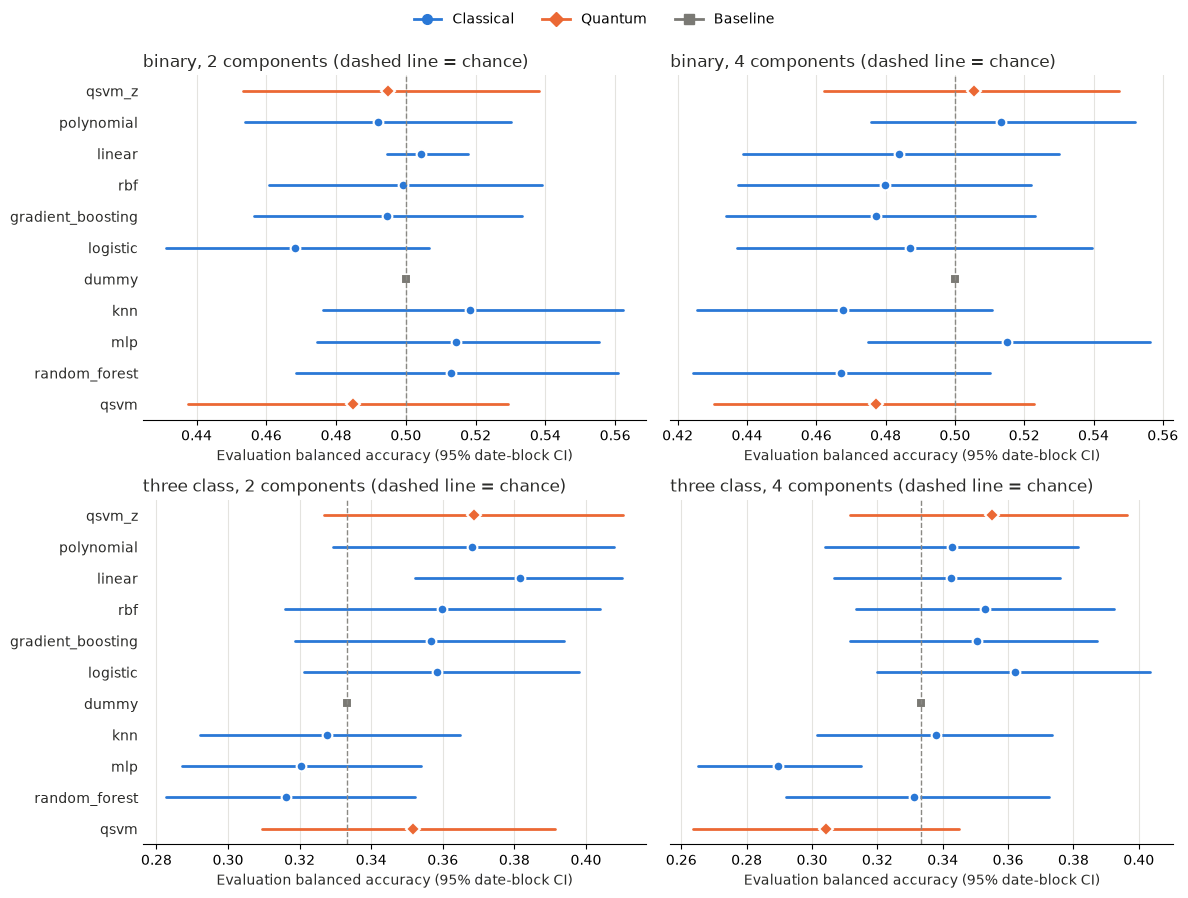

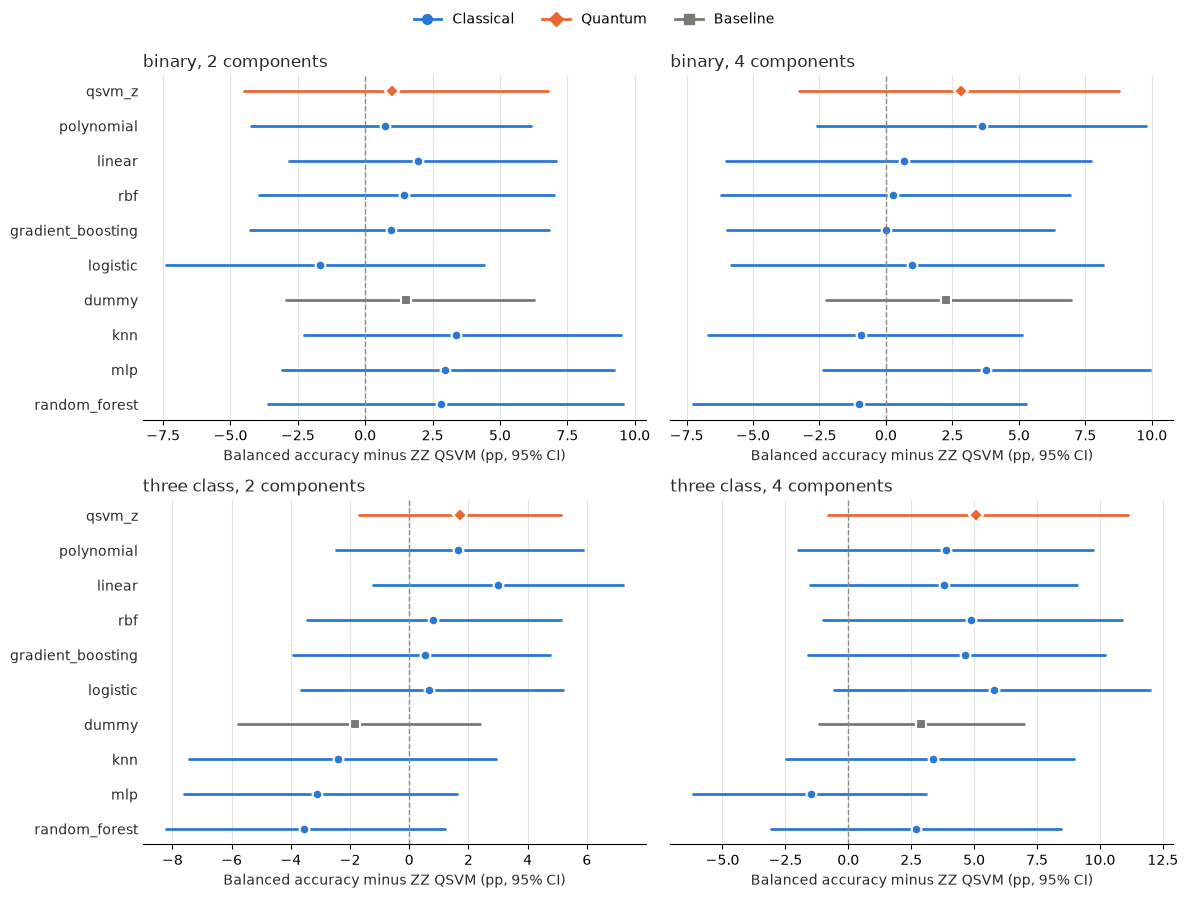

,task,dimension,model,balanced_accuracy
0,binary,2,dummy,0.500000
1,binary,2,linear,0.504376
2,binary,2,rbf,0.499317
3,binary,2,polynomial,0.492127
4,binary,2,logistic,0.468134
5,binary,2,random_forest,0.513046
6,binary,2,gradient_boosting,0.494583
7,binary,2,knn,0.518462
8,binary,2,mlp,0.514412
9,binary,2,qsvm,0.484888


In [31]:
from IPython.display import display
import pandas as pd
INCLUDE_PROJECTED_KERNEL = False
if RUN_EXPERIMENT:
    result, predictions = run(ROOT, projected=INCLUDE_PROJECTED_KERNEL)
    summary = summarise(ROOT, result, significance(predictions))
    figures(ROOT, summary)
path=ROOT/'results/expanded/metrics.csv'
if path.exists(): display(pd.read_csv(path)[['task','dimension','model','balanced_accuracy']])
else: print('Expanded study not run yet; set RUN_EXPERIMENT=True')